In [1]:
import numpy as np

class SimpleNeuron:
    def __init__(self, num_inputs, learning_rate=0.5):
        # Добавляем +1 для Bias (порога). Теперь весов будет 3 (для двух входов + bias).
        self.w = np.random.uniform(-0.5, 0.5, num_inputs + 1)
        self.lr = learning_rate

    def sigmoid(self, x):
        # Функция активации
        return 1 / (1 + np.exp(-x))

    def predict(self, inputs):
        # Добавляем 1 в конец входного вектора для Bias
        inputs_with_bias = np.append(inputs, 1)
        return self.sigmoid(np.dot(inputs_with_bias, self.w)) # np.dot перемножает и складывает (x1w1+x2w2+b)

    def train(self, X, y, epochs=100):
        for _ in range(epochs):
            for inputs, target in zip(X, y):
                # Прямой проход
                inputs_with_bias = np.append(inputs, 1)
                output = self.predict(inputs)

                # Ошибка
                # mse = (target - output)**2
                # mse' = -2*(target-output). Убираем -2, т.к. скорость обучения и читаемость кода
                error = target - output

                # Градиент для сигмоиды
                # output' = output * (1 - output)
                delta = error * output * (1 - output)

                # Обновляем веса (с учетом bias)
                # += потому что убрали -2, с -2 было бы -=
                self.w += self.lr * delta * inputs_with_bias


#Тестируем AND
print("ОБУЧЕНИЕ AND")
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

neuron_and = SimpleNeuron(num_inputs=2)
neuron_and.train(X_and, y_and, epochs=100)

print("Результаты AND (ожидаем 0, 0, 0, 1):")
for x in X_and:
    pred = neuron_and.predict(x)
    # Округляем для наглядности, чтобы было видно 0 или 1
    print(f"Вход: {x} -> Выход: {pred:.4f}", end=" -> ")
    if pred > 0.5:
      print(f"{x[0]} and {x[1]} = 1")
    else:
      print(f"{x[0]} and {x[1]} = 0")

#Тестируем OR
print("\nОБУЧЕНИЕ OR")
y_or = np.array([0, 1, 1, 1])
neuron_or = SimpleNeuron(num_inputs=2)
neuron_or.train(X_and, y_or, epochs=100)

print("Результаты OR (ожидаем 0, 1, 1, 1):")
for x in X_and:
    pred = neuron_or.predict(x)
    print(f"Вход: {x} -> Выход: {pred:.4f}", end=" -> ")
    if pred > 0.5:
      print(f"{x[0]} or {x[1]} = 1")
    else:
      print(f"{x[0]} or {x[1]} = 0")

ОБУЧЕНИЕ AND
Результаты AND (ожидаем 0, 0, 0, 1):
Вход: [0 0] -> Выход: 0.0503 -> 0 and 0 = 0
Вход: [0 1] -> Выход: 0.2575 -> 0 and 1 = 0
Вход: [1 0] -> Выход: 0.2627 -> 1 and 0 = 0
Вход: [1 1] -> Выход: 0.6999 -> 1 and 1 = 1

ОБУЧЕНИЕ OR
Результаты OR (ожидаем 0, 1, 1, 1):
Вход: [0 0] -> Выход: 0.2919 -> 0 or 0 = 0
Вход: [0 1] -> Выход: 0.8394 -> 0 or 1 = 1
Вход: [1 0] -> Выход: 0.8346 -> 1 or 0 = 1
Вход: [1 1] -> Выход: 0.9846 -> 1 or 1 = 1


Загружаем датасет MNIST
Начало обучения сети на MNIST (28x28)
Эпоха 1/10 | Средняя ошибка MSE: 0.0431
Эпоха 2/10 | Средняя ошибка MSE: 0.0260
Эпоха 3/10 | Средняя ошибка MSE: 0.0227
Эпоха 4/10 | Средняя ошибка MSE: 0.0208
Эпоха 5/10 | Средняя ошибка MSE: 0.0194
Эпоха 6/10 | Средняя ошибка MSE: 0.0183
Эпоха 7/10 | Средняя ошибка MSE: 0.0174
Эпоха 8/10 | Средняя ошибка MSE: 0.0166
Эпоха 9/10 | Средняя ошибка MSE: 0.0159
Эпоха 10/10 | Средняя ошибка MSE: 0.0153

Итоговая точность на 28x28: 87.80%



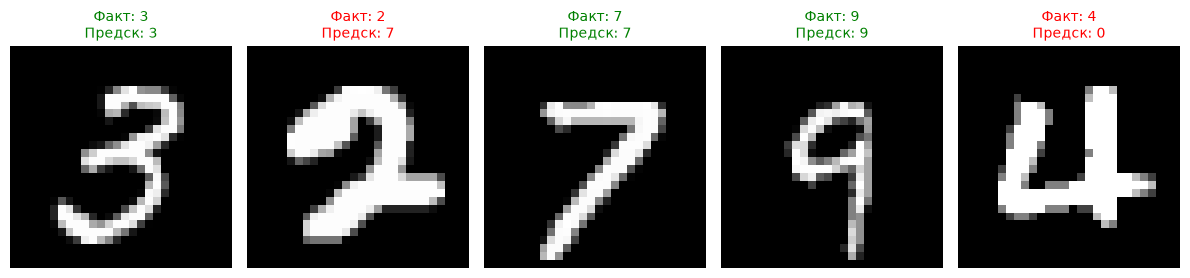

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Мой класс нейрона из первой части
class SimpleNeuron:
    def __init__(self, num_inputs, learning_rate=0.5):
        self.w = np.random.uniform(-0.5, 0.5, num_inputs + 1)
        self.lr = learning_rate

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def predict(self, inputs):
        inputs_with_bias = np.append(inputs, 1)
        return self.sigmoid(np.dot(inputs_with_bias, self.w))

    def train_step(self, inputs, target):
        inputs_with_bias = np.append(inputs, 1)
        output = self.predict(inputs)

        error = target - output
        delta = error * output * (1 - output)

        self.w += self.lr * delta * inputs_with_bias
        return error ** 2  # Квадрат ошибки для MSE

#Сеть из 10 нейронов для датасета 28x28 (784 входа)
class DigitRecognizerNetwork:
    def __init__(self, num_inputs=784, num_classes=10, learning_rate=0.5):
        self.neurons = [SimpleNeuron(num_inputs, learning_rate) for _ in range(num_classes)]

    def train(self, X, y, epochs=10):
        print("Начало обучения сети на MNIST (28x28)")
        for epoch in range(epochs):
            total_mse = 0
            for inputs, true_label in zip(X, y):
                for digit_class, neuron in enumerate(self.neurons):
                    target = 1.0 if true_label == digit_class else 0.0
                    mse = neuron.train_step(inputs, target)
                    total_mse += mse

            # Средняя квадратичная ошибка (MSE) за эпоху
            avg_mse = total_mse / (len(X) * len(self.neurons))
            print(f"Эпоха {epoch + 1}/{epochs} | Средняя ошибка MSE: {avg_mse:.4f}")

    def predict(self, inputs):
        outputs = [neuron.predict(inputs) for neuron in self.neurons]
        return np.argmax(outputs)

print("Загружаем датасет MNIST")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')
X = mnist.data.astype(np.float32) / 255.0  # Нормализация в диапазон [0, 1]
y = mnist.target.astype(np.int64)

# Берем подмножество (5000 обучающих, 1000 тестовых) для обучения
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=5000, test_size=1000, random_state=42)

# Создаем и обучаем сеть
net = DigitRecognizerNetwork(num_inputs=784, num_classes=10, learning_rate=0.5)
net.train(X_train, y_train, epochs=10)

# Проверяем общую точность на тесте
predictions = [net.predict(x) for x in X_test]
predictions = np.array(predictions)
accuracy = np.mean(predictions == y_test) * 100
print(f"\nИтоговая точность на 28x28: {accuracy:.2f}%\n")

#Визуализация результатов (вывод картинок с предсказаниями)
num_to_show = 5
random_indices = np.random.choice(len(X_test), num_to_show, replace=False)

plt.figure(figsize=(12, 3))
for i, idx in enumerate(random_indices):
    image_vector = X_test[idx]
    true_label = y_test[idx]
    predicted_label = net.predict(image_vector)

    # Возвращаем вектор 784 обратно в матрицу 28x28 для отображения
    image_2d = image_vector.reshape(28, 28)

    # Рисуем подграфик
    plt.subplot(1, num_to_show, i + 1)
    plt.imshow(image_2d, cmap='gray')

    # Цвет заголовка: зеленый, если угадали, красный, если ошиблись
    color = 'green' if predicted_label == true_label else 'red'
    plt.title(f"Факт: {true_label}\nПредск: {predicted_label}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()